<a href="https://colab.research.google.com/github/FattahulAlim/Machine_Learning_Sem5/blob/main/JS06-Regresi/TG6_Regresi_244107020018_MFattahulAlim.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Mengimpor library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
drive.mount('/content/drive')

path_dataset = '/content/drive/MyDrive/ml-sem5/JS07/dataset/insurance.csv'
data = pd.read_csv(path_dataset)
data.head()

Mounted at /content/drive


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
print("Ukuran data:", data.shape)
data.info()
print("\nJumlah missing value:")
print(data.isnull().sum())
data.describe()

Ukuran data: (1338, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

Jumlah missing value:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


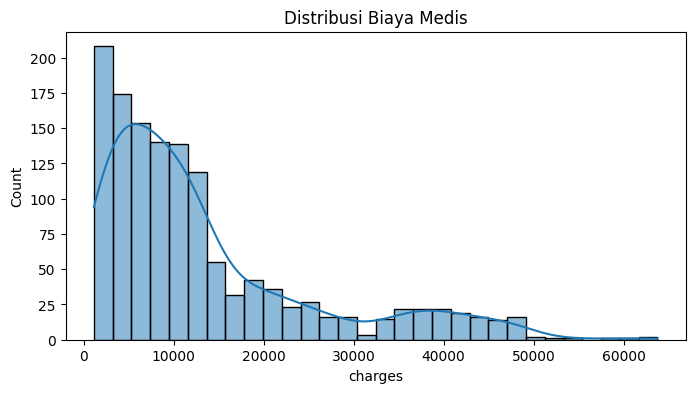

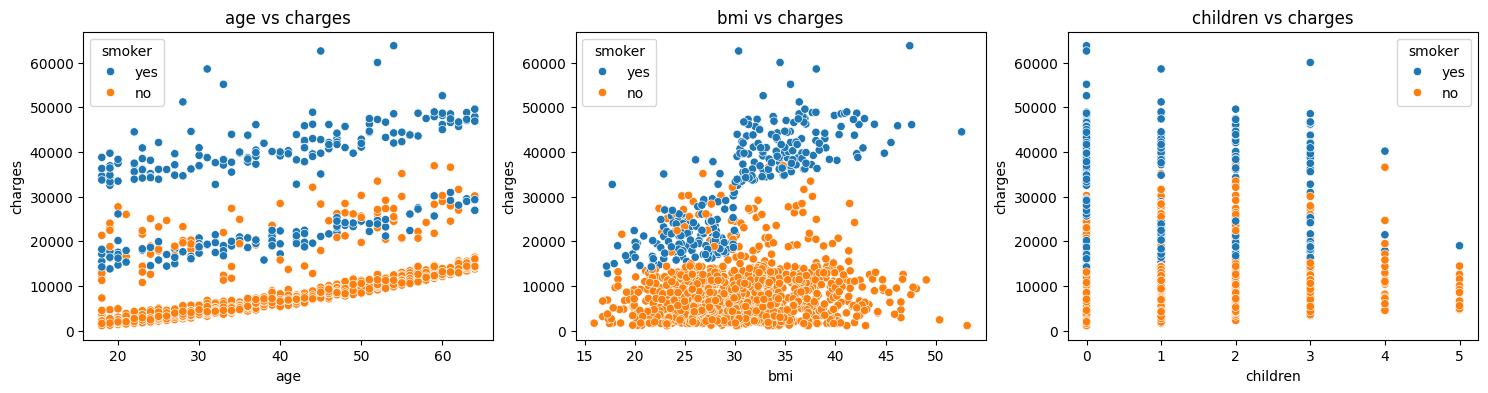

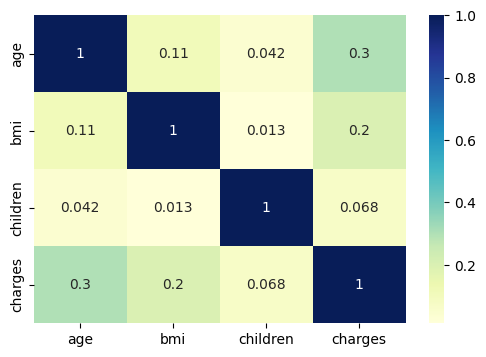

In [ ]:
# Distribusi biaya medis
plt.figure(figsize=(8, 4))
sns.histplot(data['charges'], kde=True)
plt.title('Distribusi Biaya Medis')
plt.show()

# Hubungan fitur numerik dengan charges
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, ['age', 'bmi', 'children']):
    sns.scatterplot(data=data, x=col, y='charges', hue='smoker', ax=ax)
    ax.set_title(f'{col} vs charges')
plt.show()

# Heatmap korelasi (pakai numeric_only karena ada kolom teks)
plt.figure(figsize=(6, 4))
sns.heatmap(data.corr(numeric_only=True), cmap="YlGnBu", annot=True)
plt.show()

In [ ]:
# Mengubah kolom kategorikal jadi angka (one-hot encoding)
# drop_first=True supaya tidak terjadi dummy variable trap
data_encoded = pd.get_dummies(data, columns=['sex', 'smoker', 'region'], drop_first=True)
data_encoded.head()

# Variabel bebas (X) dan target (y)
X = data_encoded.drop('charges', axis=1)
y = data_encoded['charges']

print("Fitur yang dipakai:", list(X.columns))

Fitur yang dipakai: ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

print("Data latih:", X_train.shape)
print("Data uji  :", X_test.shape)

Data latih: (1070, 8)
Data uji  : (268, 8)


In [ ]:
from sklearn.preprocessing import StandardScaler

# Scaling hanya untuk kolom numerik asli, kolom dummy (0/1) dibiarkan
kolom_numerik = ['age', 'bmi', 'children']

sc_X = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[kolom_numerik] = sc_X.fit_transform(X_train[kolom_numerik])
X_test_scaled[kolom_numerik] = sc_X.transform(X_test[kolom_numerik])  # pakai transform, bukan fit_transform

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train_scaled, y_train)

# Koefisien tiap fitur
koef = pd.DataFrame({'Fitur': X.columns, 'Koefisien': model.coef_})
print("Intercept:", model.intercept_)
koef.sort_values('Koefisien', ascending=False)

Intercept: 8884.584197182081


,Fitur,Koefisien
4,smoker_yes,23605.017267
0,age,3572.518752
1,bmi,2077.457940
2,children,528.603986
3,sex_male,-15.463728
5,region_northwest,-260.132732
7,region_southwest,-761.948706
6,region_southeast,-913.278834


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = model.predict(X_test_scaled)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R-squared:", r2)

MAE: 3933.272649405241
MSE: 31827950.22952384
RMSE: 5641.62655885019
R-squared: 0.7999876970680433


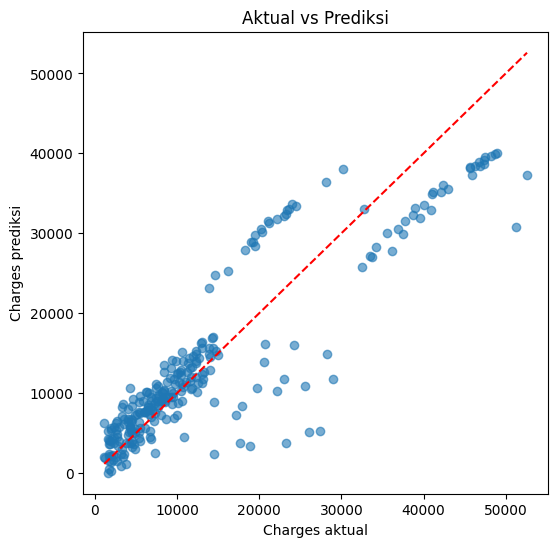

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Charges aktual')
plt.ylabel('Charges prediksi')
plt.title('Aktual vs Prediksi')
plt.show()

# Penjelasan Tentang Dataset dan deskripsi singkat variabel yang digunakan
Dataset yang dipakai adalah Medical Cost Personal Dataset (insurance.csv), berisi 1338 baris dan 7 kolom, tanpa missing value. Datanya tentang biaya medis yang ditagihkan asuransi kesehatan ke tiap orang.

|variabel|Tipe|Penjelasan|
|--|--|--|
|age|Numerik|Usia penerima asuransi (18-64 tahun)|
|sex|Kategorikal|	Jenis kelamin (female/male)|
|bmi|Numerik|Body Mass Index, indikator berat badan relatif terhadap tinggi badan|
|children|Numerik|Jumlah anak/tanggungan (0-5)|
|smoker|Kategorikal|Status perokok (yes/no)|
|region|Kategorikal|Wilayah tempat tinggal di AS (northeast, northwest, southeast, southwest)|
|charges|Numerik|Variabel target, biaya medis personal yang ditagihkan|







# Analisis hasil yang didapatkan

|variabel|Koefisien|Penjelasan|
|--|--|--|
|smoker_yes|+23.605|Perokok memiliki biaya sekitar 23.600 lebih tinggi dari non-perokok. Pengaruh terbesar.|
|age|+3.573|Kenaikan usia 1 standar deviasi menaikkan biaya sekitar 3.570.|
|bmi|+2.077|BMI lebih tinggi menaikkan biaya sekitar 2.080.|
|children|+529|Pengaruh kecil.|
|sex_male|-15|Hampir nol, jenis kelamin tidak berpengaruh berarti.|
|region|-260 sampai -913|Pengaruh kecil, dibandingkan dengan region northeast (kategori acuan).|

**Analisis Metrik**
Nilai R² pada metrik evaluasi 0,80 menunjukkan model cukup baik. RMSE (5.642) lebih besar dari MAE (3.933), menandakan ada beberapa prediksi dengan error besar, kemungkinan pada kasus biaya yang sangat tinggi.